In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import ceil, log10
from collections import deque
np.set_printoptions(precision=4, suppress=True)

,scheme,nominal_channels,edge_guard_equiv,control_channels,traffic_channels,payload_efficiency,effective_channel_equiv
0,FDMA,80,1,2,77,0.855,65.835
1,TDMA,80,8,2,70,0.673,47.143
2,TDMA_light_overhead,80,8,2,70,0.921,64.470


,dataset,scheme,attempts,blocked,blocking_pct,allocated_util_pct,useful_util_pct,wasted_pct
0,voice,FDMA,1788.65,8.9,0.49,77.92,66.62,33.38
1,voice,TDMA,1791.25,45.7,2.53,85.71,57.73,42.27
2,bursty_10pct,FDMA,1788.65,8.9,0.49,77.92,6.66,93.34
3,bursty_10pct,TDMA,1791.25,45.7,2.53,85.71,5.77,94.23
4,mix_70_30,FDMA,1788.65,8.9,0.49,77.92,48.64,51.36
5,mix_70_30,TDMA,1791.25,45.7,2.53,85.71,42.14,57.86
6,synchronized_150,FDMA,150.00,73.0,48.67,15.00,12.82,87.18
7,synchronized_150,TDMA,150.00,80.0,53.33,15.00,10.10,89.90


Erlang-B sanity check, 60 Erlangs: 0.005063327397915825 0.023744404495323924


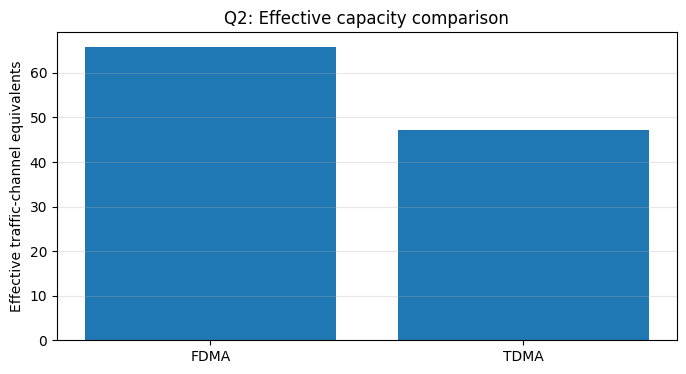

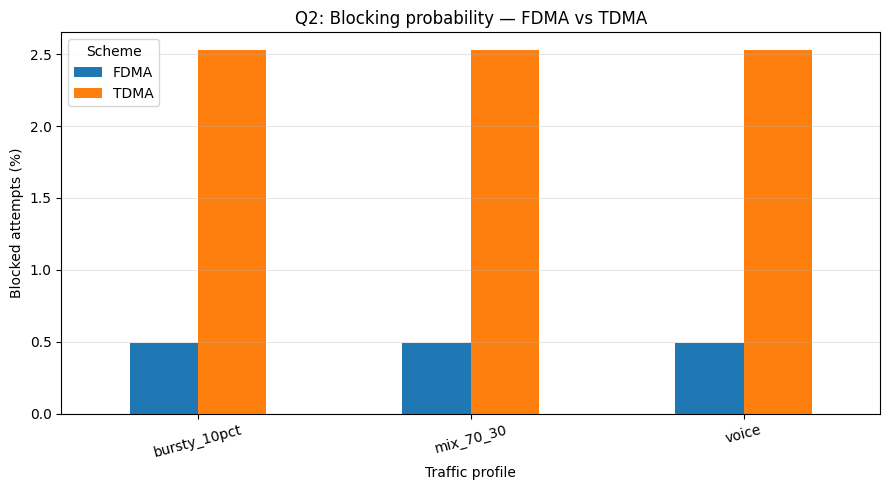

In [3]:
# Capacity assumptions from the report.
nominal = 80
fdma_channels = 77
tdma_channels = 70
fdma_eff = 0.90 * 0.95
tdma_eff = (114/156.25) * (24/26)
capacity = pd.DataFrame([
    ["FDMA", nominal, 1, 2, fdma_channels, fdma_eff, fdma_channels*fdma_eff],
    ["TDMA", nominal, 8, 2, tdma_channels, tdma_eff, tdma_channels*tdma_eff],
    ["TDMA_light_overhead", nominal, 8, 2, tdma_channels, 0.921, tdma_channels*0.921]
], columns=["scheme","nominal_channels","edge_guard_equiv","control_channels","traffic_channels","payload_efficiency","effective_channel_equiv"])
display(capacity.round(3))
capacity.to_csv("q2_capacity.csv", index=False)

def erlang_b(A, C):
    b = 1.0
    for c in range(1, C+1):
        b = (A*b)/(c + A*b)
    return b

def simulate_loss_system(channels, offered_erlangs, duration=3600, seed=2026,
                         mean_hold=120, duty=1.0, setup=0.5, synchronized=False):
    rng = np.random.default_rng(seed)
    # Poisson arrival process; exponential holding time. Each accepted call holds a channel.
    t = 0.0
    departures = []
    attempts = blocked = 0
    busy_time = 0.0
    while t < duration:
        if synchronized:
            # 150 arrivals in a short batch every 20 seconds (edge-case test).
            t += 20
            if t >= duration: break
            arrivals = [t + rng.uniform(0, 0.05) for _ in range(150)]
        else:
            rate = offered_erlangs / mean_hold
            t += rng.exponential(1/rate)
            if t >= duration: break
            arrivals = [t]
        for at in arrivals:
            attempts += 1
            departures = [d for d in departures if d > at]
            if len(departures) >= channels:
                blocked += 1
            else:
                hold = rng.exponential(mean_hold)
                departures.append(at + setup + hold)
                busy_time += (setup + hold) * duty
    blocking = blocked/attempts if attempts else 0
    allocated_util = min(1.0, offered_erlangs/channels)
    useful = allocated_util * duty
    return attempts, blocked, blocking, allocated_util, useful

traffic = []
for label, duty in [("voice",1.0),("bursty_10pct",0.1),("mix_70_30",0.73)]:
    for scheme, ch, eff in [("FDMA",77,fdma_eff),("TDMA",70,tdma_eff)]:
        vals = [simulate_loss_system(ch, 60, seed=2000+i, duty=duty) for i in range(20)]
        a,b,bl,au,uu = np.mean(vals, axis=0)
        traffic.append([label,scheme,a,b,100*bl,100*au,100*uu*eff,100-100*uu*eff])
# Synchronized batch: exactly 150 attempts per batch, compare theoretical blocking at an instant.
for scheme,ch,eff in [("FDMA",77,fdma_eff),("TDMA",70,tdma_eff)]:
    traffic.append(["synchronized_150",scheme,150, max(0,150-ch),100*max(0,150-ch)/150,15,15*eff,100-15*eff])
q2 = pd.DataFrame(traffic, columns=["dataset","scheme","attempts","blocked","blocking_pct","allocated_util_pct","useful_util_pct","wasted_pct"])
display(q2.round(2))
q2.to_csv("q2_results.csv", index=False)
print("Erlang-B sanity check, 60 Erlangs:", erlang_b(60,77), erlang_b(60,70))

# Visualisation 1: nominal effective channel capacity
plt.figure(figsize=(8,4))
labels = ["FDMA", "TDMA"]
vals = [fdma_channels*fdma_eff, tdma_channels*tdma_eff]
plt.bar(labels, vals)
plt.ylabel("Effective traffic-channel equivalents")
plt.title("Q2: Effective capacity comparison")
plt.grid(axis="y", alpha=.3)
plt.show()

# Visualisation 2: simulated blocking percentage by traffic profile
q2_plot = q2[q2["dataset"] != "synchronized_150"]
pivot_block = q2_plot.pivot(index="dataset", columns="scheme", values="blocking_pct")
pivot_block.plot(kind="bar", figsize=(9,5))
plt.ylabel("Blocked attempts (%)")
plt.xlabel("Traffic profile")
plt.title("Q2: Blocking probability — FDMA vs TDMA")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=.3)
plt.legend(title="Scheme")
plt.tight_layout()
plt.show()
